# Week 6 · Day 2 — Samples, the CLT and confidence intervals (HW 6.2 starter)

Part 0 is a walk-through. Then four TODO functions with asserts; the last cells are **HW 6.2**: the FPD intervals by channel
and by grade, the error-bar chart, and your five sentences for Bekzod.

In [1]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
DATA = Path("../..")           # this notebook lives in data/python/week6/, so "../.." is the data/ folder
AS_OF = pd.Timestamp("2026-10-01")
con = sqlite3.connect(DATA / "raw" / "nur.db")
rng = np.random.default_rng(2026)   # one seeded generator: the same "random" numbers on every run

In [2]:
# The three frames of the week (built exactly as in week 5; run, do not edit)
loans = pd.read_sql("""
    SELECT l.loan_id, l.disbursed_at, l.principal, l.term_months, l.risk_grade, l.status,
           p.code, p.name AS product, a.channel, a.credit_score, b.branch_name
    FROM loans l JOIN products p USING (product_id) JOIN applications a USING (application_id)
    JOIN branches b ON b.branch_id = l.branch_id""", con, parse_dates=["disbursed_at"])
inst = pd.read_sql("SELECT * FROM installments", con, parse_dates=["due_date"])
pay = (pd.read_sql("SELECT * FROM payments", con, parse_dates=["paid_at"])
         .sort_values("payment_id").drop_duplicates(["installment_id", "paid_at", "amount"]))   # 52 850 clean payments

# f: one row per loan whose FIRST instalment fell due on or before as-of - 30 days; fpd30 = 1 if not fully paid within 30 days
first = inst[(inst["installment_no"] == 1) & (inst["due_date"] <= AS_OF - pd.Timedelta(days=30))]
paid1 = pay[pay["paid_at"] <= AS_OF].groupby("installment_id", as_index=False).agg(paid=("amount", "sum"), first_paid=("paid_at", "min"))
f = first.merge(paid1, on="installment_id", how="left").fillna({"paid": 0})
f["fpd30"] = ((f["paid"] < f["total_due"]) | ((f["first_paid"] - f["due_date"]).dt.days > 30)).astype(int)
f = f.merge(loans, on="loan_id", validate="1:1")

# x: one row per clean payment, with its due date, days late and the loan's grade / product
x = pay.merge(inst[["installment_id", "due_date"]], on="installment_id").merge(
        loans[["loan_id", "risk_grade", "code", "channel"]], on="loan_id")
x["days_late"] = (x["paid_at"].dt.normalize() - x["due_date"]).dt.days
x["late"] = (x["paid_at"] > x["due_date"]).astype(int)
assert len(loans) == 7828 and len(f) == 7099 and f["fpd30"].sum() == 91 and len(x) == 52850
print(f"loans {len(loans)} · FPD30 {f.fpd30.sum()} / {len(f)} = {f.fpd30.mean():.2%} · clean payments {len(x)}")

loans 7828 · FPD30 91 / 7099 = 1.28% · clean payments 52850


## 0. The CLT on loan principal — a very skewed population becomes a normal sample mean

population: N 7828 · mean 51,709,668 · median 5,790,000 · sd 112,585,001 · skew 2.92


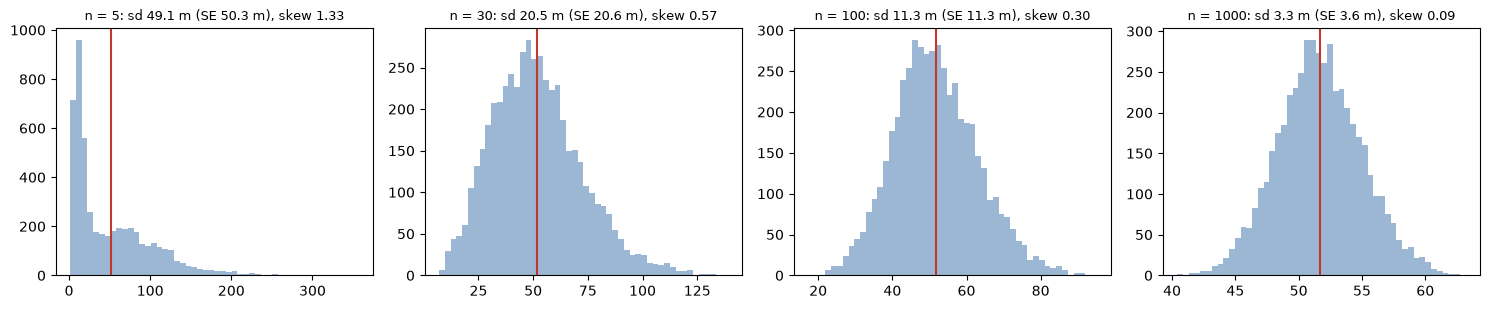

In [3]:
pop = loans["principal"].to_numpy(dtype=float)
mu, sigma = pop.mean(), pop.std()
print(f"population: N {len(pop)} · mean {mu:,.0f} · median {np.median(pop):,.0f} · sd {sigma:,.0f} · skew {stats.skew(pop):.2f}")
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, n in zip(axes, (5, 30, 100, 1000)):
    means = np.array([rng.choice(pop, n, replace=False).mean() for _ in range(5000)])
    ax.hist(means / 1e6, bins=50, color="#9bb7d4")
    ax.set_title(f"n = {n}: sd {means.std() / 1e6:.1f} m (SE {sigma / np.sqrt(n) / 1e6:.1f} m), skew {stats.skew(means):.2f}", fontsize=9)
    ax.axvline(mu / 1e6, color="#c0392b")
plt.tight_layout(); plt.show()

## 0b. z or t? One sample of 50 Consumer loans (true mean 26.93 m)

In [4]:
cons = loans.loc[loans.code == "CONS", "principal"].to_numpy(dtype=float)
smp = rng.choice(cons, 50, replace=False)
m, s, n = smp.mean(), smp.std(ddof=1), len(smp)
se = s / np.sqrt(n)
print(f"mean {m:,.0f} · s {s:,.0f} · SE {se:,.0f}")
print(f"z: {m - 1.96 * se:,.0f} … {m + 1.96 * se:,.0f}")
print(f"t (crit {stats.t.ppf(0.975, n - 1):.4f}): " + " … ".join(f"{v:,.0f}" for v in stats.t.interval(0.95, n - 1, m, se)))

mean 27,486,400 · s 12,617,221 · SE 1,784,345
z: 23,989,085 … 30,983,715
t (crit 2.0096): 23,900,625 … 31,072,175


## 1. `wald_ci(k, n, conf=0.95)` — p̂ ± z·√(p̂(1−p̂)/n), **not** clipped (a negative lower bound is the point)

In [5]:
def wald_ci(k, n, conf=0.95):
    """(lower, upper) of the Wald interval for a proportion k/n. Do not clip at 0."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [6]:
lo, hi = wald_ci(41, 2411)
assert abs(lo - 0.011837) < 1e-5 and abs(hi - 0.022174) < 1e-5
assert wald_ci(2, 150)[0] < 0            # the Wald interval goes below zero for 2 FPDs in 150 loans
print("wald_ci OK")

NotImplementedError: TODO: write me, then run the assert cell below

## 2. `wilson_ci(k, n, conf=0.95)` — the Wilson score interval
centre = (p̂ + z²/2n) / (1 + z²/n), half-width = z·√(p̂(1−p̂)/n + z²/4n²) / (1 + z²/n)

In [7]:
def wilson_ci(k, n, conf=0.95):
    """(lower, upper) of the Wilson score interval for k successes in n trials."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [8]:
from statsmodels.stats.proportion import proportion_confint
lo, hi = wilson_ci(41, 2411)
assert abs(lo - 0.012557) < 1e-5 and abs(hi - 0.022992) < 1e-5
for k, n in [(34, 3263), (16, 1425), (0, 120), (2, 150)]:
    assert np.allclose(wilson_ci(k, n), proportion_confint(k, n, method="wilson"))
print("wilson_ci OK")

NotImplementedError: TODO: write me, then run the assert cell below

## 3. `bootstrap_ci(values, stat=np.mean, B=10_000, seed=2026, conf=0.95)` — the percentile bootstrap
Resample `values` with replacement B times, compute `stat` each time, return the 2.5th and 97.5th percentiles.

In [9]:
def bootstrap_ci(values, stat=np.mean, B=10_000, seed=2026, conf=0.95):
    """(lower, upper) percentile bootstrap interval for stat(values)."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [10]:
app = f.loc[f.channel == "app", "fpd30"].to_numpy()
lo, hi = bootstrap_ci(app)
assert 0.0110 < lo < 0.0130 and 0.0215 < hi < 0.0235          # Wilson says 1.26 % … 2.30 %
assert bootstrap_ci(app) == bootstrap_ci(app)                 # seeded = repeatable
print(f"bootstrap_ci OK: {lo:.2%} … {hi:.2%}")

NotImplementedError: TODO: write me, then run the assert cell below

## 4. Bonus (HW 6.2, +20 points): `clopper_pearson(k, n, conf=0.95)` — the exact interval from the beta distribution

In [11]:
def clopper_pearson(k, n, conf=0.95):
    """(lower, upper) exact binomial interval: beta.ppf(a/2, k, n-k+1), beta.ppf(1-a/2, k+1, n-k); 0 and 1 at the edges."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [12]:
for k, n in [(41, 2411), (7, 314), (0, 120), (120, 120)]:
    assert np.allclose(clopper_pearson(k, n), proportion_confint(k, n, method="beta"))
print("clopper_pearson OK")

NotImplementedError: TODO: write me, then run the assert cell below

## HW 6.2 — `fpd_ci_table(f, by)`
One row per group: `fpd`, `n`, `rate`, `wilson_lo`, `wilson_hi`, `boot_lo`, `boot_hi` (and `cp_lo`, `cp_hi` if you did the bonus). Rates as fractions.

In [13]:
def fpd_ci_table(f, by):
    """FPD30 rate per group of `by` with its Wilson and bootstrap 95 % intervals."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [14]:
ch = fpd_ci_table(f, "channel")
gr = fpd_ci_table(f, "risk_grade")
assert ch["fpd"].tolist() == [41, 34, 16] and ch["n"].tolist() == [2411, 3263, 1425]
assert gr["fpd"].tolist() == [10, 30, 44, 7] and gr["n"].tolist() == [1667, 3084, 2034, 314]
assert abs(gr.loc[gr.index[3], "wilson_hi"] - 0.0453) < 1e-3       # grade D: 7 of 314, a wide interval
display(ch.round(4)); display(gr.round(4))

NotImplementedError: TODO: write me, then run the assert cell below

## HW 6.2 — the chart: rate as a dot, Wilson interval as an error bar, n in the label (one figure, two panels)

In [15]:
# fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
# ax[0].errorbar(x=..., y=..., yerr=[rate - lo, hi - rate], fmt="o", capsize=4)
# ...
# fig.savefig("hw62_fpd_ci.png", dpi=150, bbox_inches="tight")

## HW 6.2 — five sentences for Bekzod
1. What the intervals say about app vs branch. 2. Which interval is widest and why. 3. Wilson vs bootstrap. 4. What you would put on the dashboard tile. 5. What tomorrow's test must answer.

…